In [1]:
import vaex 
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [2]:
df       = vaex.open('iom_catalogue_6col.hdf5')


In [10]:
df.column_names

['orig_idx',
 'En',
 'Lz',
 'Lperp',
 'feh',
 'progenitor_id',
 'excluded_from_KS',
 'cluster_labels',
 'cluster_labels_added',
 'dm_group_labels',
 'dm_group_labels_added',
 'ks_group_labels',
 'ks_group_labels_added']

/cosma/apps/durham/dc-dodd1/lib/python3.12/site-packages/vaex/viz/mpl.py:315: UserWarning: `plot` is deprecated and it will be removed in version 5.x. Please `df.viz.heatmap` instead.
  warnings.warn('`plot` is deprecated and it will be removed in version 5.x. Please `df.viz.heatmap` instead.')


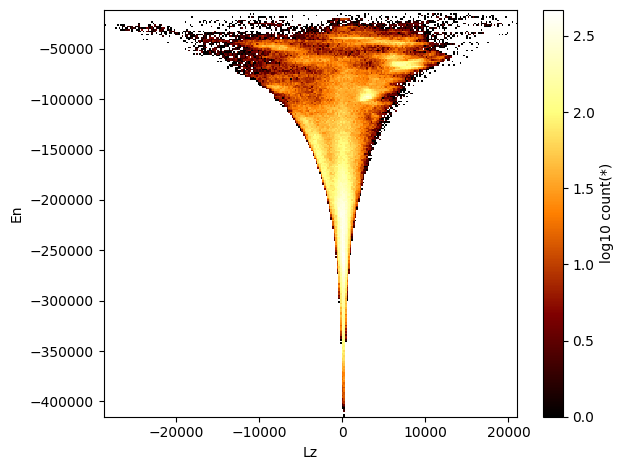

In [5]:
df.plot('Lz','En',f='log10')

In [6]:
from scipy.cluster.hierarchy import linkage as sc_linkage, fcluster
from collections import Counter
from tqdm import tqdm

# ── Scale IoM to [-1, 1] using pipeline bounds from YAML ─────────────────────
# En:[-420000, -10000], Lperp:[0, 31400], Lz:[-29400, 29400]
En    = df['En'].values
Lperp = df['Lperp'].values
Lz    = df['Lz'].values

En_sc    = 2*(En    - (-420000)) / (-10000  - (-420000)) - 1
Lperp_sc = 2*(Lperp -       0 ) / ( 31400  -       0  ) - 1
Lz_sc    = 2*(Lz    - (-29400)) / ( 29400  - (-29400) ) - 1
iom_scaled = np.column_stack([En_sc, Lperp_sc, Lz_sc])
raw_cluster = df['cluster_labels'].values   # or whatever the column is called
# ── Cluster IDs ─────────────────────────
cluster_ids = np.array(sorted(np.unique(raw_cluster[raw_cluster >= 0]).tolist()))
n_cl = len(cluster_ids)
print(f"{n_cl} clusters")

# ── Mahalnobis distance between cluster IoM distributions ──────────────
def _mahal(m1, m2, cov1, cov2):
    a = m2 - m1
    b = np.linalg.inv(cov1 + cov2)
    return float(a @ b @ a)

n_pairs = n_cl * (n_cl - 1) // 2
dm = np.empty(n_pairs, dtype=np.float64)
k = 0
for i in tqdm(range(n_cl - 1), desc="distance matrix"):
    ci   = cluster_ids[i]
    U    = iom_scaled[raw_cluster == ci]
    mu_i = U.mean(axis=0)
    cov_i = np.cov(U.T) if len(U) >= 2 else np.eye(3)
    for j in range(i + 1, n_cl):
        cj   = cluster_ids[j]
        V    = iom_scaled[raw_cluster == cj]
        mu_j = V.mean(axis=0)
        cov_j = np.cov(V.T) if len(V) >= 2 else np.eye(3)
        dm[k] = np.sqrt(_mahal(mu_i, mu_j, cov_i, cov_j))
        k += 1

Z_mahalanobis = sc_linkage(dm, method='single')
print(f"Z shape: {Z_mahalanobis.shape}  (expect ({n_cl-1}, 4))")
print(f"distance range: {dm.min():.3f} – {dm.max():.3f}")


428 clusters


distance matrix: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 427/427 [00:43<00:00,  9.84it/s]

Z shape: (427, 4)  (expect (427, 4))
distance range: 0.424 – 412.302


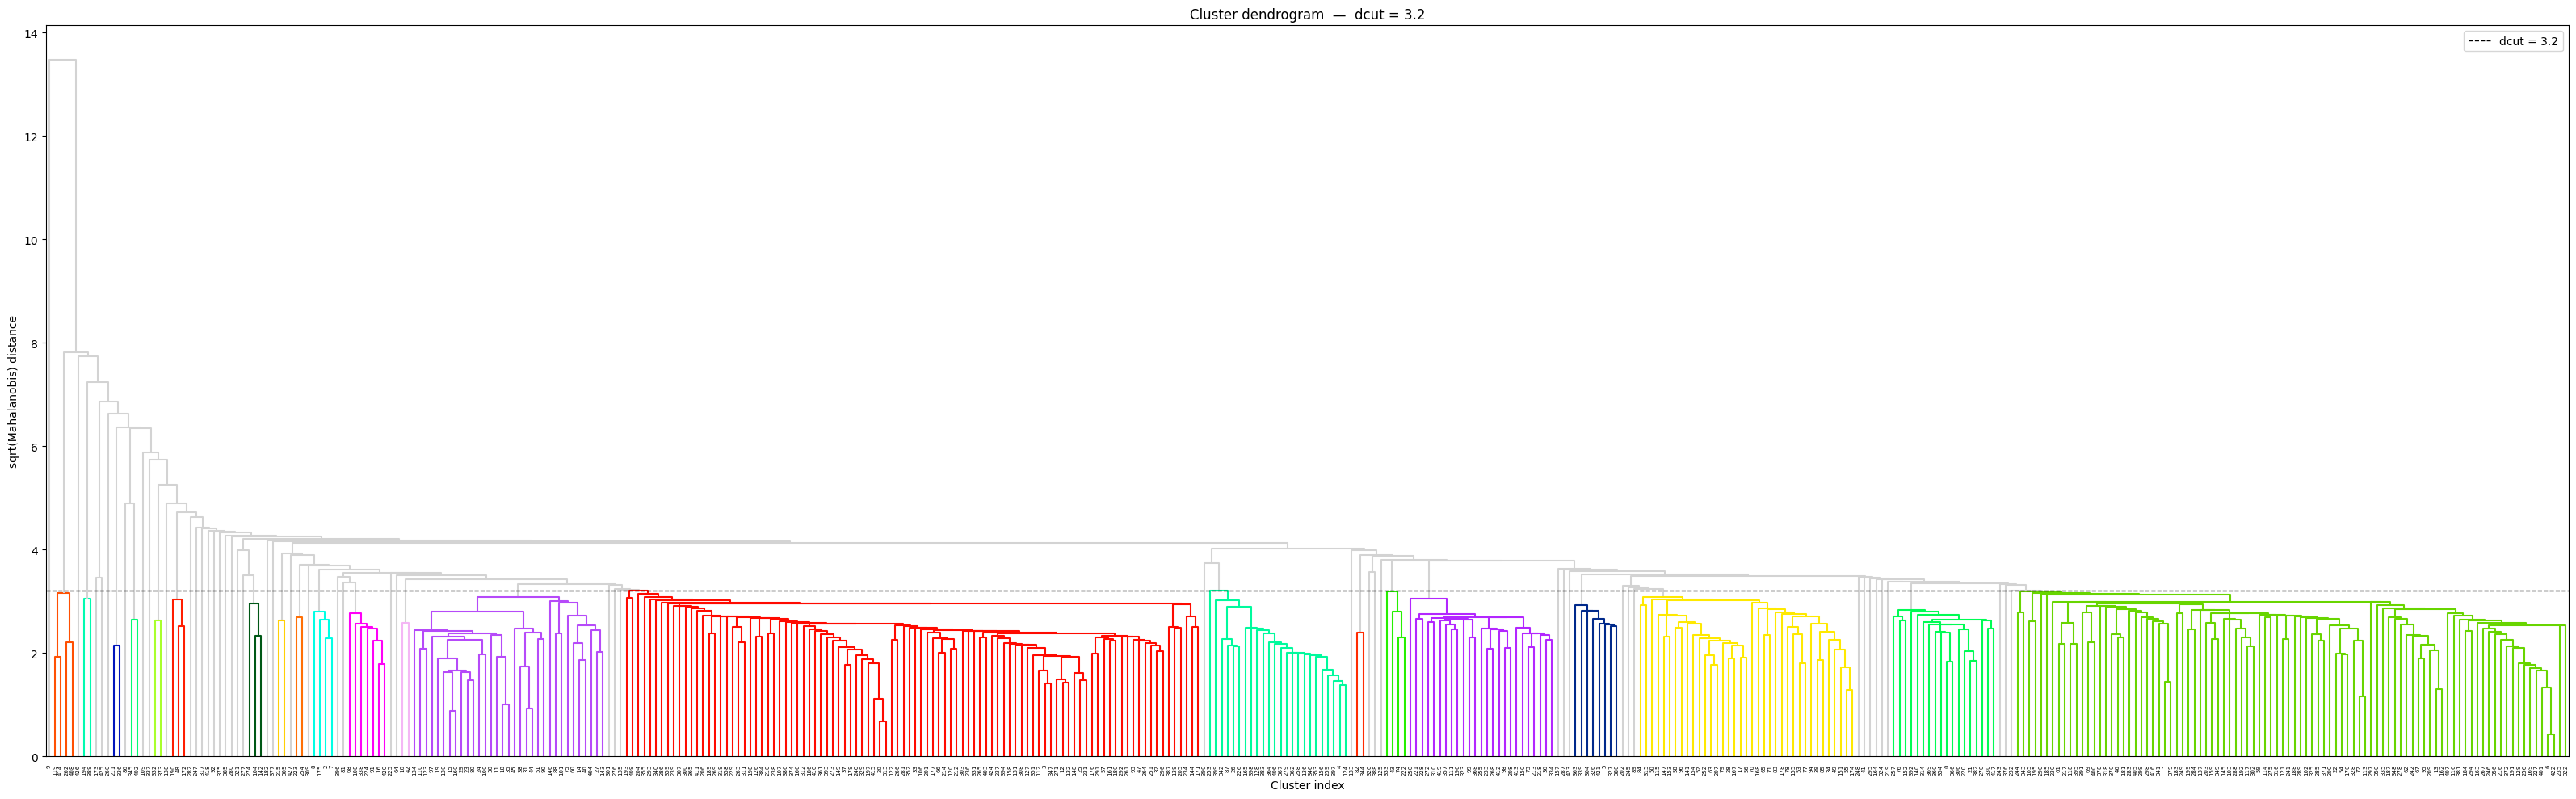

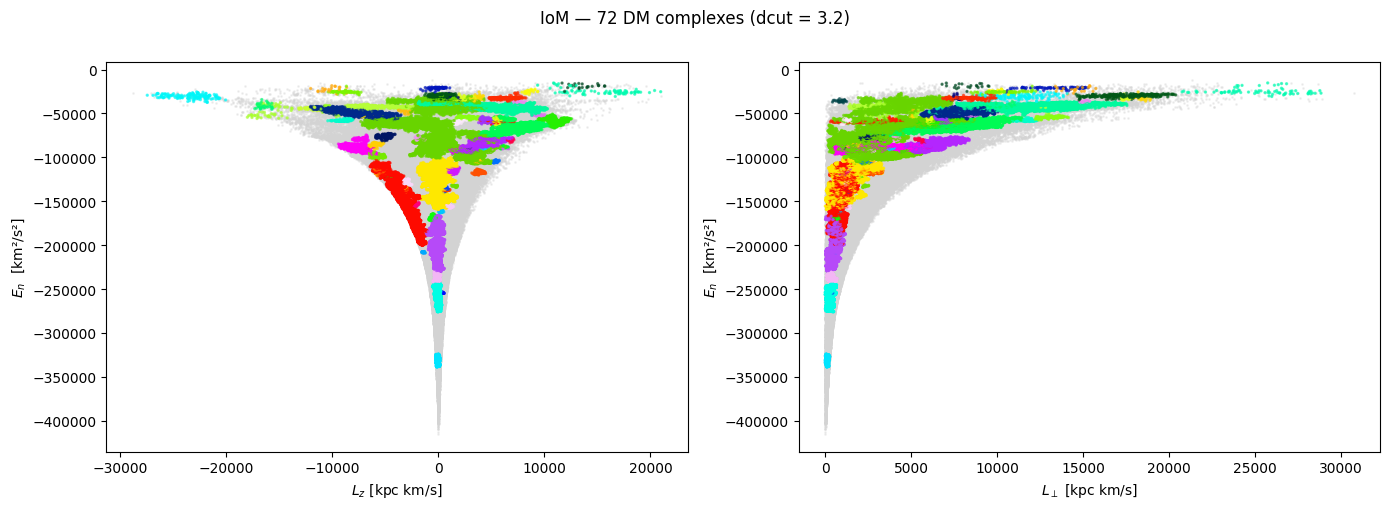

In [8]:
from scipy.cluster.hierarchy import dendrogram, fcluster
from matplotlib.colors import to_hex
import matplotlib.pyplot as plt
import numpy as np
import random

# ── 1. DM groups ──────────────────────────────────────────────────────────────
dm_from_Z = fcluster(Z_mahalanobis, 3.2, criterion='distance')
dm_unique  = np.unique(dm_from_Z)
n_groups   = len(dm_unique)

# ── 2. Single colour map shared by both plots ─────────────────────────────────
random.seed(42)
raw_cols = [plt.cm.gist_ncar(i / n_groups) for i in range(n_groups)]
random.shuffle(raw_cols)
palette = [to_hex(c) for c in raw_cols]
dm_id_to_colour = {int(dm_unique[i]): palette[i] for i in range(n_groups)}

n_cl = len(cluster_ids)
node_dm = {i: int(dm_from_Z[i]) for i in range(n_cl)}   # leaves
for step, row in enumerate(Z_mahalanobis):
    left, right = int(row[0]), int(row[1])
    merge_node  = n_cl + step
    dl, dr      = node_dm.get(left, -1), node_dm.get(right, -1)
    node_dm[merge_node] = dl if dl == dr else -1  # -1 = cross-DM merge

def link_color_func(k):
    return dm_id_to_colour.get(node_dm.get(k, -1), 'lightgrey')

# ── 4. Dendrogram ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(32, 10))
ddata = dendrogram(
    Z_mahalanobis, ax=ax, no_labels=False,
    link_color_func=link_color_func,   # overrides color_threshold colouring
)
ax.axhline(3.2, color='k', lw=1, ls='--', label='dcut = 3.2')
ax.set_xlabel('Cluster index')
ax.set_ylabel('sqrt(Mahalanobis) distance')
ax.set_title('Cluster dendrogram  —  dcut = 3.2')
ax.legend()
plt.tight_layout()
plt.show()

# ── 5. Per-star DM label ──────────────────────────────────────────────────────
star_dm_label = np.full(len(df), -1, dtype=int)
for cl_idx, cl_id in enumerate(cluster_ids):
    star_dm_label[raw_cluster == cl_id] = int(dm_from_Z[cl_idx])

# ── 6. IoM — same dm_id_to_colour, guaranteed match ──────────────────────────
mask_dm = star_dm_label >= 0
star_colours_dm = np.array([
    dm_id_to_colour.get(int(star_dm_label[i]), '#cccccc')
    for i in range(len(df))
])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, xcol, xlabel in zip(axes,
                             ['Lz',          'Lperp'],
                             ['$L_z$ [kpc km/s]', '$L_\\perp$ [kpc km/s]']):
    ax.scatter(df[xcol].values[~mask_dm], df['En'].values[~mask_dm],
               s=1, c='lightgrey', alpha=0.3, rasterized=True)
    ax.scatter(df[xcol].values[mask_dm],  df['En'].values[mask_dm],
               s=2, c=star_colours_dm[mask_dm], alpha=0.6, rasterized=True)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('$E_n$  [km²/s²]')

plt.suptitle(f'IoM — {n_groups} DM complexes (dcut = 3.2)', y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# IoM space: KC cluster membership
# Left:  stars coloured by cluster_labels       (original KC cluster members)
# Right: stars coloured by cluster_labels_added  (ellipsoid-added members)
# Same colour palette so matching clusters share a colour across panels.

from matplotlib.colors import to_hex
import random

En_all = df['En'].values
Lz_all = df['Lz'].values

orig_labels  = df['cluster_labels'].values
added_labels = df['cluster_labels_added'].values

# Build colour map from original cluster IDs
ids   = np.unique(orig_labels[orig_labels >= 0])
n_ids = len(ids)
random.seed(42)
raw_cols = [plt.cm.gist_ncar(i / max(n_ids, 1)) for i in range(n_ids)]
random.shuffle(raw_cols)
id_to_col = {int(ids[i]): to_hex(raw_cols[i]) for i in range(n_ids)}

mask_orig  = orig_labels  >= 0
mask_added = added_labels >= 0

orig_col_arr  = np.array([id_to_col.get(int(orig_labels[i]),  '#cccccc')
                           for i in np.where(mask_orig)[0]])
added_col_arr = np.array([id_to_col.get(int(added_labels[i]), '#cccccc')
                           for i in np.where(mask_added)[0]])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Left: original members
ax = axes[0]
ax.scatter(Lz_all[~mask_orig], En_all[~mask_orig],
           s=0.3, c='#cccccc', alpha=0.2, rasterized=True)
ax.scatter(Lz_all[mask_orig],  En_all[mask_orig],
           s=1.5, c=orig_col_arr, alpha=0.7, rasterized=True)
ax.set_xlabel('$L_z$ [kpc km/s]'); ax.set_ylabel('$E_n$ [km$^2$/s$^2$]')
ax.set_title(f'cluster_labels  ({mask_orig.sum():,} stars)', fontsize=10)

# Right: ellipsoid-added members
ax = axes[1]
ax.scatter(Lz_all[~mask_added], En_all[~mask_added],
           s=0.3, c='#cccccc', alpha=0.2, rasterized=True)
ax.scatter(Lz_all[mask_added],  En_all[mask_added],
           s=1.5, c=added_col_arr, alpha=0.7, rasterized=True)
ax.set_xlabel('$L_z$ [kpc km/s]')
ax.set_title(f'cluster_labels_added  ({mask_added.sum():,} stars)', fontsize=10)

plt.suptitle('IoM space — $L_z$ vs $E_n$', y=1.01)
plt.tight_layout()
plt.show()


In [ ]:
# Velocity space: DM complex members in Cartesian velocities
# Three projections: vx-vy, vx-vz, vz-vy
# Coloured by DM complex (same palette as dendrogram in cell 6)
# vx, vy, vz come from LabelledSample (df_extra), aligned via orig_idx

orig_idx = df['orig_idx'].values
vx_all   = df_extra['vx'].values[orig_idx]   # km/s, Cartesian x
vy_all   = df_extra['vy'].values[orig_idx]   # km/s, Cartesian y
vz_all   = df_extra['vz'].values[orig_idx]   # km/s, Cartesian z

dm_v     = df['dm_group_labels'].values
dm_add_v = df['dm_group_labels_added'].values
in_dm_v  = (dm_v >= 0) | (dm_add_v >= 0)

star_colours_v = np.array([
    dm_id_to_colour.get(int(dm_v[i] if dm_v[i] >= 0 else dm_add_v[i]), '#cccccc')
    if in_dm_v[i] else '#cccccc'
    for i in range(len(vx_all))
])

projections_v = [
    (vx_all, vy_all, '$v_x$ [km/s]', '$v_y$ [km/s]'),
    (vx_all, vz_all, '$v_x$ [km/s]', '$v_z$ [km/s]'),
    (vz_all, vy_all, '$v_z$ [km/s]', '$v_y$ [km/s]'),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (xv, yv, xl, yl) in zip(axes, projections_v):
    ax.scatter(xv[~in_dm_v], yv[~in_dm_v],
               s=0.3, c='#dddddd', alpha=0.2, rasterized=True)
    ax.scatter(xv[in_dm_v],  yv[in_dm_v],
               s=1.5, c=star_colours_v[in_dm_v], alpha=0.6, rasterized=True)
    ax.set_xlabel(xl); ax.set_ylabel(yl)

plt.suptitle('Velocity space — DM complexes coloured as in dendrogram')
plt.tight_layout()
plt.show()


In [ ]:
# Multi-panel diagnostic for one KS group
# Top row:  IoM projections, stars coloured by their KC cluster membership
# Bottom:   MCP bar — progenitor fraction for each cluster in the group

from matplotlib.colors import to_hex
import random

TARGET_KS_GROUP = 0   # <-- change to any KS group ID

ks_orig_col  = df['ks_group_labels'].values
ks_add_col   = df['ks_group_labels_added'].values
kc_col       = df['cluster_labels'].values
prog_col     = df['progenitor_id'].values
feh_col      = df['feh'].values
En_col       = df['En'].values
Lz_col       = df['Lz'].values
Lperp_col    = df['Lperp'].values

# stars in this KS group (original + added)
in_group = (ks_orig_col == TARGET_KS_GROUP) | (ks_add_col == TARGET_KS_GROUP)
is_orig  =  ks_orig_col == TARGET_KS_GROUP

kc_in_group = np.unique(kc_col[is_orig])
kc_in_group = kc_in_group[kc_in_group >= 0]
n_kc = len(kc_in_group)

# colour each KC cluster
random.seed(0)
kc_cols_raw = [plt.cm.tab20(i % 20) for i in range(n_kc)]
random.shuffle(kc_cols_raw)
kc_to_col = {int(cid): to_hex(kc_cols_raw[i]) for i, cid in enumerate(kc_in_group)}

star_col = np.array([
    kc_to_col.get(int(kc_col[i]), '#aaaaaa') if in_group[i] else '#dddddd'
    for i in range(len(En_col))
])

fig = plt.figure(figsize=(15, 9))
gs  = fig.add_gridspec(2, 3, height_ratios=[2, 1], hspace=0.35, wspace=0.3)

projections = [
    (Lz_col,    En_col,    '$L_z$ [kpc km/s]',    '$E_n$ [km²/s²]'),
    (Lperp_col, En_col,    '$L_\\perp$ [kpc km/s]', '$E_n$ [km²/s²]'),
    (Lz_col,    Lperp_col, '$L_z$ [kpc km/s]',    '$L_\\perp$ [kpc km/s]'),
]

for col, (xv, yv, xl, yl) in enumerate(projections):
    ax = fig.add_subplot(gs[0, col])
    ax.scatter(xv[~in_group], yv[~in_group],
               s=0.5, c='#dddddd', alpha=0.3, rasterized=True)
    ax.scatter(xv[in_group],  yv[in_group],
               s=4,   c=star_col[in_group], alpha=0.8, rasterized=True)
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    n_orig_g  = is_orig.sum()
    n_added_g = in_group.sum() - n_orig_g
    ax.set_title(f'KS group {TARGET_KS_GROUP}  |  '
                 f'{n_orig_g} orig + {n_added_g} added  |  '
                 f'{n_kc} clusters', fontsize=9)

# MCP bar: progenitor fractions per cluster
ax_bar = fig.add_subplot(gs[1, :])
prog_counts_total = Counter(prog_col[is_orig])
top_progs = [p for p, _ in sorted(prog_counts_total.items(),
                                   key=lambda x: -x[1])[:8]]

bar_w = 0.7
for ci, cid in enumerate(kc_in_group):
    mask_cl = is_orig & (kc_col == cid)
    n_cl_stars = mask_cl.sum()
    if n_cl_stars == 0:
        continue
    prog_cl = Counter(prog_col[mask_cl])
    bottom = 0
    for pi, prog in enumerate(top_progs):
        frac = prog_cl.get(prog, 0) / n_cl_stars
        if frac > 0:
            ax_bar.bar(ci, frac, bar_w, bottom=bottom,
                       color=plt.cm.Set2(pi / max(len(top_progs), 1)),
                       label=str(prog) if ci == 0 else '')
            bottom += frac
    # 'other' remainder
    other = 1 - bottom
    if other > 0.005:
        ax_bar.bar(ci, other, bar_w, bottom=bottom, color='#cccccc',
                   label='other' if ci == 0 else '')
    # colour the bar edge to match the IoM cluster colour
    for patch in ax_bar.patches[-int(np.ceil(1/max(other,1e-9))):]:
        pass   # edge colouring omitted for clarity
    ax_bar.axvline(ci - bar_w/2, color='white', lw=0.5)

ax_bar.set_xticks(range(n_kc))
ax_bar.set_xticklabels([str(c) for c in kc_in_group], fontsize=7, rotation=45)
ax_bar.set_ylabel('Progenitor fraction')
ax_bar.set_xlabel('KC cluster ID')
ax_bar.set_ylim(0, 1)
ax_bar.legend(title='Progenitor', bbox_to_anchor=(1.01, 1), loc='upper left',
              fontsize=8, title_fontsize=8)
ax_bar.set_title(f'Progenitor composition per cluster — KS group {TARGET_KS_GROUP}',
                 fontsize=9)

plt.suptitle(f'Group {TARGET_KS_GROUP} diagnostic', fontsize=12, fontweight='bold')
plt.show()
